# 03b · Optional: variational quantum classifier with a sigmoid output

Second quantum model from the synopsis (marked "if time permits"). It is a small re-uploading circuit:

* 2 layers of [ $R_y(c\,x_q)$ encoding on each qubit, trainable $R_z$, $R_y$ on each qubit, CX(0,1), CX(1,2) ],
* readout $\langle Z \rangle$ on qubit 2, the end of the CX ladder (a local readout, so no barren plateau at this size),
* output $p_{SAFE} = \sigma(w \langle Z\rangle + b)$, trained with binary cross entropy and COBYLA.

Parameters: 12 circuit angles + 2 classical = 14, close to the 16 of the small MLP baseline.
Encoding $R_y$ and trainable $R_z$ do not commute, so the layers do not collapse (NB05 lesson).
Training uses the exact `StatevectorEstimator` (no shot noise) to keep the run short.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from scipy.optimize import minimize

from qsvm_rc import config, data_utils, metrics

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "qsvm")

VQC_LAYERS = 2
VQC_BANDWIDTH = 1 # angles already span [0, pi]
VQC_SIZES = [80, 160]
VQC_SEEDS = [0, 1, 2]
VQC_MAXITER = 300

In [3]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, band_mask = data_utils.test_indices(splits)
x_test, y_test = data_utils.features_and_labels(frame, test_rows, scaler)

## 1. The circuit

Circuit parameters: 15  plus 2 classical (w, b)


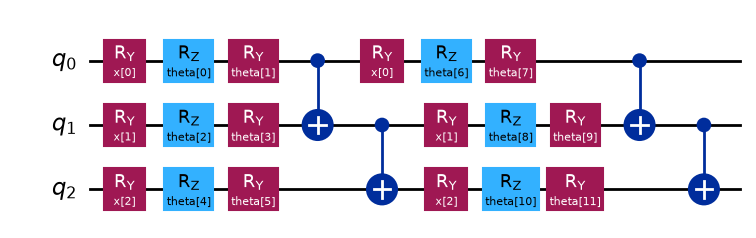

In [4]:
data_parameters = ParameterVector("x", 3)
weight_parameters = ParameterVector("theta", 6 * VQC_LAYERS)

vqc_circuit = QuantumCircuit(3)
for layer in range(VQC_LAYERS):
    for qubit in range(3):
        vqc_circuit.ry(data_parameters[qubit], qubit)
    for qubit in range(3):
        vqc_circuit.rz(weight_parameters[6 * layer + 2 * qubit], qubit)
        vqc_circuit.ry(weight_parameters[6 * layer + 2 * qubit + 1], qubit)
    vqc_circuit.cx(0, 1)
    vqc_circuit.cx(1, 2)

# Pauli strings read right to left, so "ZII" is Z on qubit 2
readout = SparsePauliOp("ZII")
estimator = StatevectorEstimator()
parameter_order = list(vqc_circuit.parameters)
print("Circuit parameters:", len(parameter_order), " plus 2 classical (w, b)")
display(vqc_circuit.draw("mpl", fold = -1))

In [5]:
def expectation_values(angles, weights):
    """<Z_2> for every row of angles, in one Estimator job. Rows are bound by parameter, never by position."""
    lookup = {weight_parameters[k]: weights[k] for k in range(len(weight_parameters))}
    rows = []
    for point in VQC_BANDWIDTH * np.asarray(angles):
        for qubit in range(3):
            lookup[data_parameters[qubit]] = point[qubit]
        rows.append([lookup[parameter] for parameter in parameter_order])
    result = estimator.run([(vqc_circuit, readout, np.array(rows))]).result()[0]
    return np.asarray(result.data.evs)


def sigmoid(values):
    return 1 / (1 + np.exp(-values))


def binary_cross_entropy(probabilities, labels):
    targets = (labels + 1) / 2
    probabilities = np.clip(probabilities, 1e-8, 1 - 1e-8)
    return -np.mean(targets * np.log(probabilities) + (1 - targets) * np.log(1 - probabilities))


def train_vqc(x_train, y_train, seed, maxiter = VQC_MAXITER):
    rng = np.random.default_rng(seed)
    initial = np.concatenate([rng.uniform(0, 2 * np.pi, len(weight_parameters)), [1, 0]])
    history = []

    def loss(all_parameters):
        logits = all_parameters[-2] * expectation_values(x_train, all_parameters[:-2]) + all_parameters[-1]
        value = binary_cross_entropy(sigmoid(logits), y_train)
        history.append(value)
        return value

    result = minimize(loss, initial, method = "COBYLA", options = {"maxiter": maxiter})
    return result.x, history


def predict_vqc(all_parameters, angles):
    logits = all_parameters[-2] * expectation_values(angles, all_parameters[:-2]) + all_parameters[-1]
    return np.where(sigmoid(logits) >= 0.5, 1, -1)

## 2. Train on the saved training sets and score on the fixed test set

In [6]:
vqc_rows = []
histories = {}
for size in VQC_SIZES:
    for train_seed in VQC_SEEDS:
        rows = data_utils.training_indices(splits, size, train_seed, "random")
        x_train, y_train = data_utils.features_and_labels(frame, rows, scaler)
        start = time.time()
        trained, history = train_vqc(x_train, y_train, config.run_seed(config.SEED, train_seed))
        predictions = predict_vqc(trained, x_test)
        row = {"section": SECTION, "model": "vqc", "strategy": "random", "train_size": size,
               "train_seed": train_seed, "seconds": time.time() - start, "final_loss": history[-1]}
        row.update(metrics.test_set_metrics(y_test, predictions, band_mask))
        vqc_rows.append(row)
        histories[(size, train_seed)] = history
        band_error = row["band_error"]
        balanced_accuracy = row["test_balanced_accuracy"]
        seconds = row["seconds"]
        print(f"n={size:<4} seed={train_seed}  band_error={band_error:.3f}  test_bal_acc={balanced_accuracy:.3f}  ({seconds:.0f} s)")
        pd.DataFrame(vqc_rows).to_csv(RESULTS_DIR / "vqc_results.csv", index = False)
vqc_results = pd.DataFrame(vqc_rows)

n=80   seed=0  band_error=0.481  test_bal_acc=0.845  (41 s)
n=80   seed=1  band_error=0.476  test_bal_acc=0.837  (28 s)
n=80   seed=2  band_error=0.461  test_bal_acc=0.883  (26 s)
n=160  seed=0  band_error=0.452  test_bal_acc=0.888  (45 s)
n=160  seed=1  band_error=0.465  test_bal_acc=0.832  (48 s)
n=160  seed=2  band_error=0.468  test_bal_acc=0.880  (45 s)


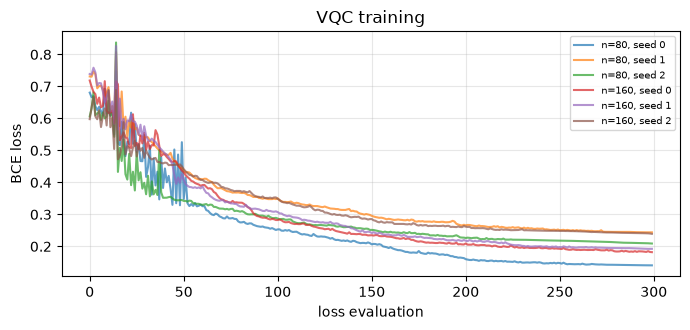

In [7]:
figure = plt.figure(figsize = (7, 3.4))
for (size, train_seed), history in histories.items():
    plt.plot(history, alpha = 0.7, label = f"n={size}, seed {train_seed}")
plt.xlabel("loss evaluation")
plt.ylabel("BCE loss")
plt.title("VQC training")
plt.legend(fontsize = 7)
plt.grid(alpha = 0.3)
plt.tight_layout()
figure.savefig(config.figures_dir() / "vqc_loss_curves.png", dpi = 200)
plt.show()

In [8]:
comparison = vqc_results.copy()
for path in [config.section_results_dir(SECTION, "classical") / "learning_curves_random.csv",
             RESULTS_DIR / "learning_curves_random.csv"]:
    if path.exists():
        other = pd.read_csv(path)
        other = other[other["train_size"].isin(VQC_SIZES) & other["train_seed"].isin(VQC_SEEDS)]
        comparison = pd.concat([comparison, other[other["model"].isin(["mlp_small", "mlp", "rbf_svm", "qsvm_angle", "qsvm_zz"])]], ignore_index = True)
metrics.mean_ci_table(comparison, ["band_error", "test_balanced_accuracy", "test_f1", "test_false_safe_rate"])

band_error test_balanced_accuracy  \
model      train_size                                           
mlp        80          0.410 +/- 0.152        0.949 +/- 0.057   
           160         0.365 +/- 0.204        0.974 +/- 0.038   
mlp_small  80          0.414 +/- 0.076        0.962 +/- 0.035   
           160         0.397 +/- 0.035        0.973 +/- 0.007   
qsvm_angle 80          0.439 +/- 0.095        0.953 +/- 0.088   
           160         0.384 +/- 0.072        0.978 +/- 0.019   
qsvm_zz    80          0.401 +/- 0.073        0.964 +/- 0.037   
           160         0.416 +/- 0.055        0.956 +/- 0.052   
rbf_svm    80          0.430 +/- 0.058        0.948 +/- 0.023   
           160         0.356 +/- 0.030        0.984 +/- 0.002   
vqc        80          0.473 +/- 0.026        0.855 +/- 0.060   
           160         0.462 +/- 0.021        0.867 +/- 0.075   

                               test_f1 test_false_safe_rate  
model      train_size                                        
mlp        80          0.934 +/- 0.050      0.023 +/- 0.027  
           160         0.964 +/- 0.049      0.017 +/- 0.018  
mlp_small  80          0.951 +/- 0.031      0.018 +/- 0.016  
           160         0.959 +/- 0.017      0.025 +/- 0.037  
qsvm_angle 80          0.941 +/- 0.082      0.015 +/- 0.034  
           160         0.967 +/- 0.026      0.018 +/- 0.046  
qsvm_zz    80          0.952 +/- 0.027      0.019 +/- 0.030  
           160         0.940 +/- 0.069      0.028 +/- 0.039  
rbf_svm    80          0.931 +/- 0.023      0.026 +/- 0.006  
           160         0.974 +/- 0.011      0.017 +/- 0.016  
vqc        80          0.815 +/- 0.079      0.043 +/- 0.010  
           160         0.828 +/- 0.094      0.050 +/- 0.029

Same seeds and rows for every model in this table. Next: `04_ablations/01_encoding_ablations.ipynb`.